# 01 · The staircase: hard rounding, STE and the soft (sigmoid) staircase

**Goal of this notebook:** understand the one function at the heart of `vvtk_quant` and how it differs
from the *straight-through estimator* (STE) that most quantization papers use.

We work only with 1-D curves here, no networks yet. Each step is short: read, run, look at the figure.

| Step | What you will see |
|---|---|
| 1 | the hard staircase $Q(x)$ and why its gradient is useless |
| 2 | the STE: trick, theory (latent weights + projection), clipped STE, oscillation |
| 3 | the soft staircase $Q_T(x)$ and its temperature $T$ |
| 4 | gradients: STE vs soft staircase |
| 5 | absolute vs relative temperature (a real bug of v0.x) |
| 6 | the fast version used in training |
| 7 | a toy fit: STE vs soft vs soft + anchor, 10 seeds |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

## Setup
Run from `examples/` inside a clone of the repo (`pip install -e .` once at the repo root), or on Colab after
cloning it (the repo is private: you need to be a collaborator).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))          # use the clone's vvtk_quant when running from examples/
import torch
import numpy as np
import matplotlib.pyplot as plt
import vvtk_quant
from vvtk_quant import quant, ste_quant, dquant, dquant_fast
print("vvtk_quant", vvtk_quant.__version__, "| torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

vvtk_quant 1.0.0 | torch 2.5.1+cu121


## Step 1 · The hard staircase

A quantizer with $L$ **levels** $l_0 < l_1 < \dots < l_{L-1}$ sends every value to its nearest level:

$$Q(x) = l_{k(x)}, \qquad k(x) = \arg\min_k |x - l_k| .$$

The points where the output jumps are the **bin limits** (midpoints) $m_i = \tfrac{1}{2}(l_i + l_{i+1})$.

> 📘 **Common practice.** Nearest-level rounding is what every quantizer deploys. Read: Nagel et al. white paper
> (arXiv:2106.08295), §2.

We take 4 levels, deliberately *not* evenly spaced (vvtk_quant allows any levels).

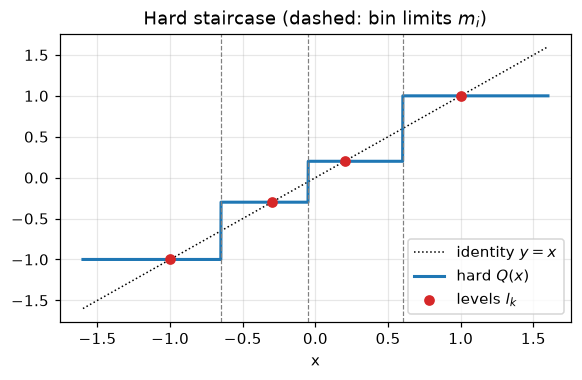

In [3]:
levels = torch.tensor([-1.0, -0.3, 0.2, 1.0])
limits = (levels[:-1] + levels[1:]) / 2
x = torch.linspace(-1.6, 1.6, 2001)

xq, idx = quant(x, levels)

plt.figure(figsize=(6, 3.4))
plt.plot(x, x, "k:", lw=1, label="identity $y=x$")
plt.plot(x, xq, lw=2, label="hard $Q(x)$")
for m in limits: plt.axvline(m, color="gray", ls="--", lw=0.8)
plt.scatter(levels, levels, color="C3", zorder=3, label="levels $l_k$")
plt.title("Hard staircase (dashed: bin limits $m_i$)"); plt.xlabel("x"); plt.legend(); plt.show()

**The problem:** $Q$ is flat almost everywhere, so $\dfrac{dQ}{dx} = 0$ (and infinite at the limits).
Backpropagation through $Q$ gives **zero gradient**: the weights would never move.

In [4]:
xg = x.clone().requires_grad_(True)
print("Q(x) carries a gradient?", quant(xg, levels)[0].requires_grad, "-> the index lookup cuts the graph")

Q(x) carries a gradient? False -> the index lookup cuts the graph


## Step 2 · The straight-through estimator (STE)

### 2a · The trick
STE (Hinton's lectures 2012; analysed by Bengio, Léonard & Courville 2013, arXiv:1308.3432) **lies in the backward
pass**: use $Q(x)$ forward, but pretend it was the identity backward:

$$\text{forward: } y = Q(x), \qquad \text{backward: } \frac{\partial y}{\partial x} := 1 .$$

In PyTorch this is one line: `y = x + (Q(x) - x).detach()`. The value is $Q(x)$; the only term that carries a
gradient is $x$. That is exactly `ste_quant`.

> 📘 **Common practice.** STE is the default QAT method in almost every paper and toolkit (TensorFlow Lite, PyTorch
> `FakeQuantize`, BitNet). Read: Bengio et al. 2013 (arXiv:1308.3432), BinaryConnect (arXiv:1511.00363), Yin et al.
> 2019 (arXiv:1903.05662). Everything in Step 2 is textbook material.

In [5]:
xg = x.clone().requires_grad_(True)
y = ste_quant(xg, levels)
y.sum().backward()
print("forward equals hard Q:", torch.allclose(y.detach(), xq, atol=1e-6))
print("gradient values:", xg.grad.unique().tolist(), " <- 1 everywhere, whatever the level layout")

forward equals hard Q: True
gradient values: [1.0]  <- 1 everywhere, whatever the level layout


### 2b · What STE optimizes: latent weights + projection

With STE the network keeps a float **latent** weight $w$ (the "master copy"), and the deployed weight is its
projection $\hat w = Q(w)$. For a loss $\mathcal{L}$ one SGD step is

$$w_{t+1} = w_t - \eta\, \nabla_{\hat w}\mathcal{L}(\hat w_t), \qquad \hat w_t = Q(w_t).$$

The gradient is **evaluated at the quantized point** $\hat w_t$ but **applied to the latent point** $w_t$. This is
BinaryConnect (Courbariaux et al. 2015, arXiv:1511.00363) and, in optimization language, a *lazy projection* /
dual-averaging method: $w$ accumulates small gradients until the sum is large enough to cross a limit $m_i$, and only
then does $\hat w$ change level. Many tiny updates that would be lost by rounding are **remembered** in $w$.

### 2c · Why it works (when it works), and its error
A first-order expansion around the latent weight:

$$\mathcal{L}(Q(w)) \approx \mathcal{L}(w) + \nabla\mathcal{L}(w)^\top \big(Q(w) - w\big) .$$

STE uses $\nabla\mathcal{L}(Q(w))$ instead of the true gradient of $\mathcal{L}(Q(w))$ (which is 0). It is a good
descent direction when $\nabla\mathcal{L}(Q(w)) \approx \nabla\mathcal{L}(w)$, i.e. when the quantization error
$Q(w)-w$ is small compared with the curvature scale of the loss: **fine levels (8 bits) yes, 2–3 bits less so**.
Yin et al. (ICLR 2019, arXiv:1903.05662) prove that, for a suitably chosen STE, the "coarse gradient" correlates
positively with the true population gradient, and that a bad choice of STE makes training unstable near some minima.

### 2d · The clipped STE
Plain STE also passes gradient to weights far **outside** the grid, which then drift without changing $\hat w$.
The common variant (BinaryConnect, BNNs) clips:

$$\frac{\partial \hat w}{\partial w} := \mathbb{1}\big[l_0 \le w \le l_{L-1}\big] .$$

### 2e · STE's known failure: oscillation
If the best quantized solution needs a value between two levels, the latent weight converges **to a limit**
$m_i$, and gradient noise makes $\hat w$ jump between $l_i$ and $l_{i+1}$ at every few steps (Nagel et al., ICML 2022,
arXiv:2203.11086). We will see this in Step 7.

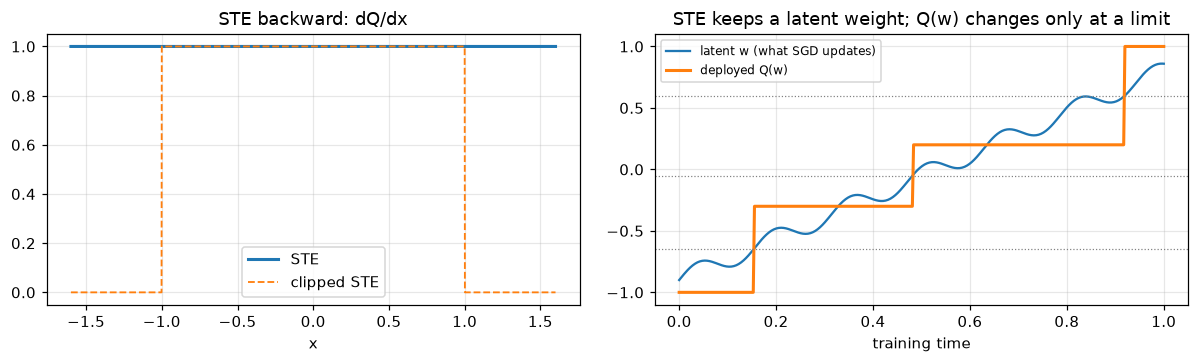

In [6]:
def ste_clipped(x, levels):
    """STE with gradient 1 inside [l_0, l_{L-1}] and 0 outside."""
    lo, hi = levels[0], levels[-1]
    xc = x.clamp(lo, hi)                 # clamp has gradient 1 inside, 0 outside
    return xc + (quant(x.detach(), levels)[0] - xc).detach()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name, f in [("STE", ste_quant), ("clipped STE", ste_clipped)]:
    xg = x.clone().requires_grad_(True); f(xg, levels).sum().backward()
    ax[0].plot(x, xg.grad, label=name, lw=2 if name == "STE" else 1.2, ls="-" if name == "STE" else "--")
ax[0].set_title("STE backward: dQ/dx"); ax[0].legend(); ax[0].set_xlabel("x")
# latent vs deployed: a latent weight path and its projection
t = torch.linspace(0, 1, 400)
w_path = -0.9 + 1.7 * t + 0.08 * torch.sin(40 * t)
ax[1].plot(t, w_path, label="latent w (what SGD updates)")
ax[1].plot(t, quant(w_path, levels)[0], label="deployed Q(w)", lw=2)
for m in limits: ax[1].axhline(m, color="gray", ls=":", lw=0.8)
ax[1].set_title("STE keeps a latent weight; Q(w) changes only at a limit"); ax[1].legend(fontsize=8); ax[1].set_xlabel("training time")
plt.tight_layout(); plt.show()

STE gradient is the same for a weight sitting exactly on a level and for a weight that is about to jump to the
next level. It carries **no information about the staircase**: that is the gap vvtk_quant tries to fill.

## Step 3 · The soft staircase

Replace each jump of height $\Delta_i = l_{i+1} - l_i$ by a sigmoid centred at its limit:

$$Q_T(x) = l_0 + \sum_{i=0}^{L-2} \Delta_i \,\sigma\!\big(T\,(x - m_i)\big), \qquad \sigma(z) = \frac{1}{1+e^{-z}} .$$

* $T \to \infty$: every sigmoid becomes a step, $Q_T \to Q$.
* $T$ small: the staircase melts into a smooth ramp.

So during training we **anneal** $T$ from small to large: the network first sees a smooth function, and at the end
the hard one. This is `dquant` (reference implementation: one sigmoid per step).

> 📗 **Known, less common.** Soft staircases annealed to hard rounding are published (DSQ, Gong et al. 2019,
> arXiv:1908.05033, uses tanh pieces on a **uniform** grid; soft-to-hard quantization, Agustsson et al. 2017,
> arXiv:1704.00648), but most practitioners use STE.
>
> 🧪 **vvtk_quant.** The same sum of sigmoids on **arbitrary, non-uniform levels** (Lloyd, quantiles, FP tables), one
> sigmoid per gap $\Delta_i$.

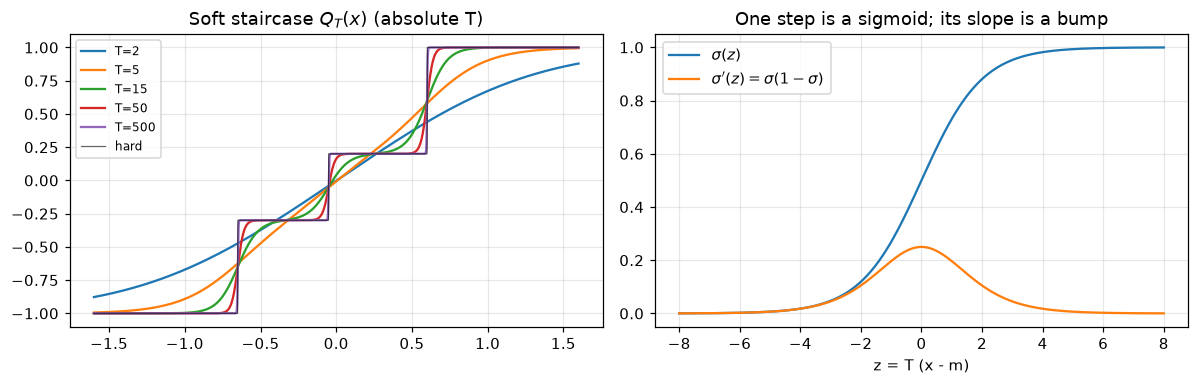

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for T in [2, 5, 15, 50, 500]:
    ax[0].plot(x, dquant(x, levels, temp=T, eps=0.0), label=f"T={T}")
ax[0].plot(x, xq, "k", lw=0.8, alpha=0.6, label="hard")
ax[0].set_title("Soft staircase $Q_T(x)$ (absolute T)"); ax[0].legend(fontsize=8)
# one step = one sigmoid
z = torch.linspace(-8, 8, 400)
ax[1].plot(z, torch.sigmoid(z), label=r"$\sigma(z)$")
ax[1].plot(z, torch.sigmoid(z) * (1 - torch.sigmoid(z)), label=r"$\sigma'(z)=\sigma(1-\sigma)$")
ax[1].set_title("One step is a sigmoid; its slope is a bump"); ax[1].set_xlabel("z = T (x - m)"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 4 · Gradients: STE vs soft staircase

Differentiating $Q_T$:

$$\frac{dQ_T}{dx} = \sum_i \Delta_i\, T\, \sigma\big(T(x-m_i)\big)\big(1-\sigma\big(T(x-m_i)\big)\big) .$$

A sum of bumps, one per limit, each of area $\Delta_i$. **A weight near a limit gets a large gradient (it can still
change level); a weight sitting on a level gets almost none (it is "decided").** STE gives 1 everywhere.

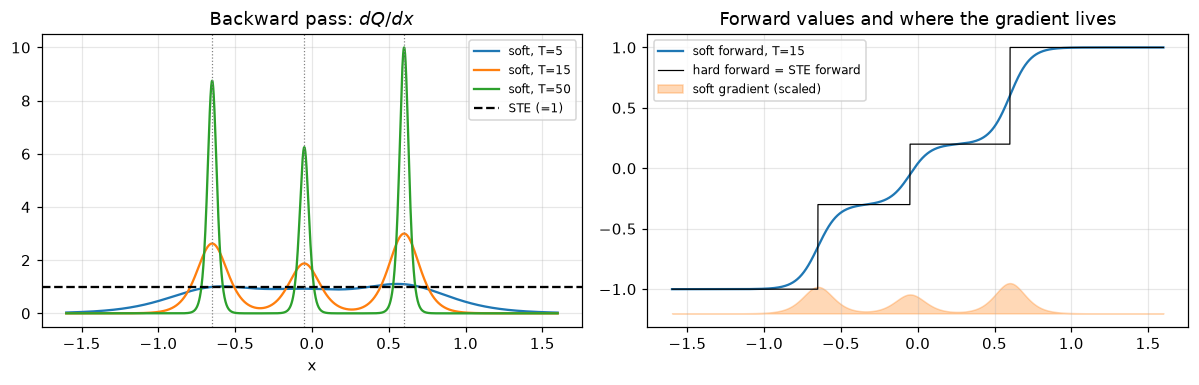

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for T in [5, 15, 50]:
    xg = x.clone().requires_grad_(True)
    dquant(xg, levels, temp=T, eps=0.0).sum().backward()
    ax[0].plot(x, xg.grad, label=f"soft, T={T}")
ax[0].axhline(1, color="k", ls="--", label="STE (=1)")
for m in limits: ax[0].axvline(m, color="gray", ls=":", lw=0.8)
ax[0].set_title("Backward pass: $dQ/dx$"); ax[0].legend(fontsize=8); ax[0].set_xlabel("x")
# where does the gradient go? fraction of gradient mass within ±10% of a step around a limit
T = 15
xg = x.clone().requires_grad_(True); dquant(xg, levels, temp=T, eps=0.0).sum().backward()
ax[1].plot(x, dquant(x, levels, temp=T, eps=0.0), label=f"soft forward, T={T}")
ax[1].plot(x, xq, "k", lw=0.8, label="hard forward = STE forward")
ax[1].fill_between(x, -1.2, -1.2 + 0.25 * xg.grad / xg.grad.max(), alpha=0.3, color="C1", label="soft gradient (scaled)")
ax[1].set_title("Forward values and where the gradient lives"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

|  | forward | backward | forward == deployed model? |
|---|---|---|---|
| STE | $Q(x)$ (exact) | 1 (blind to levels) | yes, always |
| soft staircase | $Q_T(x)$ (approximate) | bumps at the limits | only when $T$ is large |

The soft staircase trades a **forward mismatch** for an **informative gradient**. The annealing of $T$ is what
closes the mismatch. That is why, in later notebooks, we always evaluate the **hard** model.

## Step 5 · Absolute vs relative temperature

In v0.x, $T$ was absolute: $\sigma(T(x-m_i))$. The width of a step in $x$ units is then about $4/T$, whatever the
gap $\Delta_i$. Real weights are small (|w| ~ 0.01–0.1) and at 4 bits the gaps are ~0.005: with $T=500$ the
"staircase" is still a ramp. Training then reports the accuracy of a **soft** model that is not the deployed one.

v1.0 measures $T$ in units of the local step (`relative=True`, default in the layers):

$$Q_T(x) = l_0 + \sum_i \Delta_i\, \sigma\!\Big(\frac{T}{\Delta_i}(x - m_i)\Big) .$$

Now $T=5$ means "a step whose transition takes ~ 80 % of the bin", at any scale and any bit width.

> 🧪 **vvtk_quant (small modification).** Dividing $T$ by the local gap $\Delta_i$ is a small change, but it matters
> with non-uniform levels, where gaps differ by 10x inside one tensor. On a uniform grid DSQ's per-interval formulation is
> implicitly relative. It also fixed a real v0.x bug (see the README).

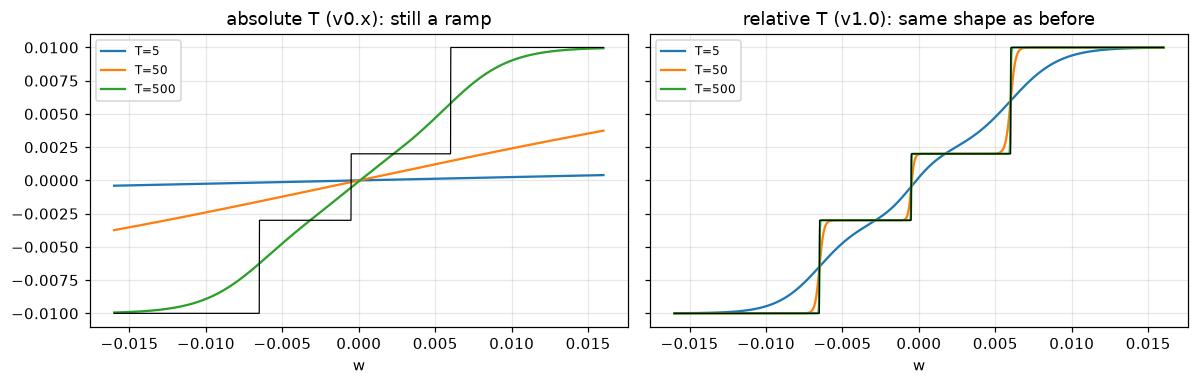

In [9]:
w_levels = levels * 0.01                     # the same staircase, at a realistic weight scale
xw = x * 0.01
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for T in [5, 50, 500]:
    ax[0].plot(xw, dquant(xw, w_levels, temp=T, eps=0.0), label=f"T={T}")
    ax[1].plot(xw, dquant(xw, w_levels, temp=T, relative=True), label=f"T={T}")
for a, t in zip(ax, ["absolute T (v0.x): still a ramp", "relative T (v1.0): same shape as before"]):
    a.plot(xw, quant(xw, w_levels)[0], "k", lw=0.8); a.set_title(t); a.legend(fontsize=8); a.set_xlabel("w")
plt.tight_layout(); plt.show()

A number to remember: with relative temperature, the soft value of a weight sitting exactly **on** a level
differs from the level by $\approx \Delta\,\sigma(-T/2)$ on each side. The gap between the soft and hard models
therefore shrinks like $e^{-T/2}$:

In [10]:
for T in [1, 2, 5, 10, 20, 40]:
    print(f"T={T:>3}:  sigma(-T/2) = {torch.sigmoid(torch.tensor(-T / 2)).item():.2e}")

T=  1:  sigma(-T/2) = 3.78e-01
T=  2:  sigma(-T/2) = 2.69e-01
T=  5:  sigma(-T/2) = 7.59e-02
T= 10:  sigma(-T/2) = 6.69e-03
T= 20:  sigma(-T/2) = 4.54e-05
T= 40:  sigma(-T/2) = 2.06e-09


## Step 6 · The fast version used in training

`dquant` loops over all $L-1$ steps: fine for 16 levels, too slow and memory-hungry for 256 levels times millions
of weights. `dquant_fast` keeps only the **two steps around the bin** of $x$ (index $c$):

$$Q^{\text{fast}}_T(x) = l_c - \Delta_{c-1}\,\big(1-\sigma_{\text{left}}\big) + \Delta_c\,\sigma_{\text{right}} .$$

For relative $T \gtrsim 4$ the other sigmoids are saturated and the two agree. Let us check.

> 🧪 **vvtk_quant (implementation detail).** The two-neighbour approximation is ours; it is an engineering choice, not a
> research claim.

T= 1: max |full - fast| = 0.2540
T= 4: max |full - fast| = 0.0297
T=15: max |full - fast| = 0.0000


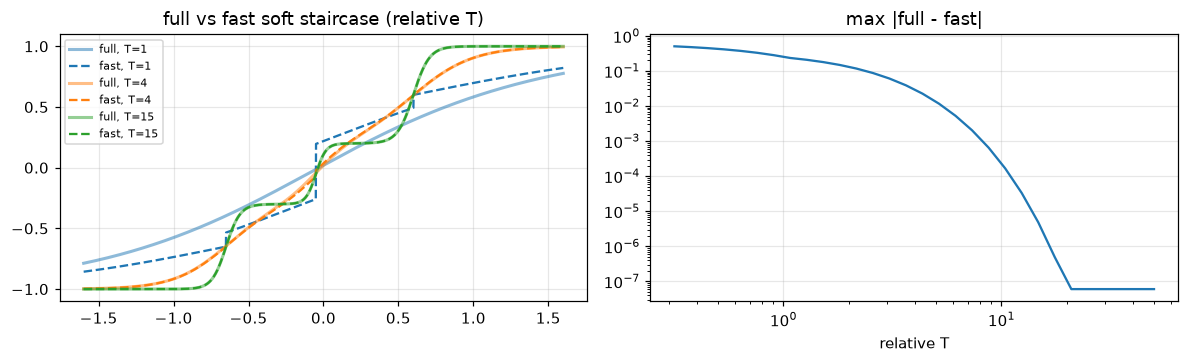

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for T, c in [(1, "C0"), (4, "C1"), (15, "C2")]:
    ax[0].plot(x, dquant(x, levels, temp=T, relative=True), c, lw=2, alpha=0.5, label=f"full, T={T}")
    ax[0].plot(x, dquant_fast(x, levels, temp=T, relative=True), c + "--", label=f"fast, T={T}")
    err = (dquant(x, levels, temp=T, relative=True) - dquant_fast(x, levels, temp=T, relative=True)).abs().max()
    print(f"T={T:>2}: max |full - fast| = {err:.4f}")
ax[0].set_title("full vs fast soft staircase (relative T)"); ax[0].legend(fontsize=7)
Ts = torch.logspace(-0.5, 1.7, 30)
ax[1].semilogy(Ts, [(dquant(x, levels, temp=float(T), relative=True) - dquant_fast(x, levels, temp=float(T), relative=True)).abs().max() + 1e-9 for T in Ts])
ax[1].set_xscale("log"); ax[1].set_xlabel("relative T"); ax[1].set_title("max |full - fast|")
plt.tight_layout(); plt.show()

**Practical rule:** start the anneal at $T\approx 2$–$4$ (the fast version is a good approximation) and end at
$T \gtrsim 30$ (soft ≈ hard to better than $10^{-6}$ of a step).

## Step 7 · A toy fit: one weight, STE vs soft staircase vs soft + anchor

The smallest possible "training": a single weight $w$ must make $Q(w)\,a$ match a target $y = t\,a$ for random
inputs $a$. We put the target $t=-0.04$ **just right of the limit** $m=-0.05$ (between levels $-0.3$ and $0.2$), the
situation where STE oscillates. The best deployed value is the level nearest to $t$, i.e. $0.2$.

Three methods, same optimizer, same 300 steps, geometric anneal $T: 2 \to 40$:

* **STE**: $\hat w = Q(w)$, gradient 1.
* **soft**: $\hat w = Q_T(w)$.
* **soft + anchor**: soft, plus $\lambda\,(Q_T(w) - Q(w))^2$, a penalty on the distance between the soft value and
  the nearest level (the "MSE anchor"; notebook 05 studies it).

> 📗/🧪 Pulling weights to the grid with a penalty or a prox step is published (ProxQuant, arXiv:1810.00861); the
> anchor *together with* the soft staircase, and its forms in notebook 05, are the vvtk_quant variant.

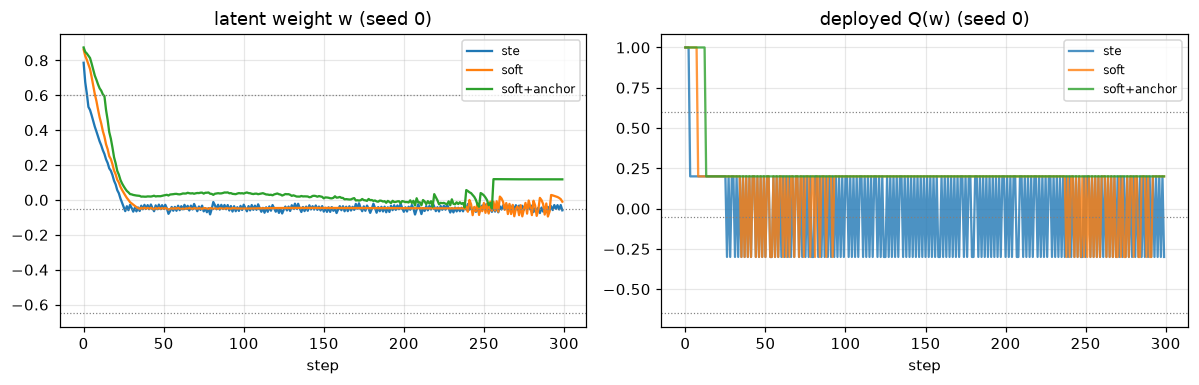

In [ ]:
def toy(method, target=-0.04, steps=300, lr=0.05, T0=2.0, T1=40.0, seed=0, lam=1.0):
    torch.manual_seed(seed)
    w = torch.tensor(0.9, requires_grad=True)
    opt = torch.optim.SGD([w], lr=lr)
    hist_w, hist_q = [], []
    for s in range(steps):
        a = torch.randn(64)
        T = T0 * (T1 / T0) ** (s / (steps - 1))              # geometric anneal
        wq = ste_quant(w, levels) if method == "ste" else dquant_fast(w, levels, temp=T, relative=True)
        loss = ((wq * a - target * a) ** 2).mean()
        if method == "soft+anchor":
            loss = loss + lam * (wq - quant(w.detach(), levels)[0]) ** 2
        opt.zero_grad(); loss.backward(); opt.step()
        hist_w.append(w.item()); hist_q.append(quant(w.detach(), levels)[0].item())
    return np.array(hist_w), np.array(hist_q)

methods = ["ste", "soft", "soft+anchor"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for method in methods:
    hw, hq = toy(method, seed=0)
    ax[0].plot(hw, label=method); ax[1].plot(hq, label=method, alpha=0.8)
for a in ax:
    for m in limits: a.axhline(m, color="gray", ls=":", lw=0.8)
    a.set_xlabel("step"); a.legend(fontsize=8)
ax[0].set_title("latent weight w (seed 0)"); ax[1].set_title("deployed Q(w) (seed 0)")
plt.tight_layout(); plt.show()

One seed is an anecdote. Ten seeds:

In [25]:
print(f"{'method':<12} | {'level changes (all)':>20} | {'changes, last 100 steps':>24} | {'ends on best level 0.2':>22}")
print("-" * 88)
for method in methods:
    runs = [toy(method, seed=s) for s in range(10)]
    ch = [int((np.diff(q) != 0).sum()) for _, q in runs]
    ch100 = [int((np.diff(q[-100:]) != 0).sum()) for _, q in runs]
    best = sum(abs(q[-1] - 0.2) < 1e-6 for _, q in runs)
    print(f"{method:<12} | {np.mean(ch):10.1f} ± {np.std(ch):5.1f}     | {np.mean(ch100):12.1f} ± {np.std(ch100):5.1f}     | {best:>14d} / 10")

method       |  level changes (all) |  changes, last 100 steps | ends on best level 0.2
----------------------------------------------------------------------------------------
ste          |      247.9 ±   5.8     |         89.5 ±   4.1     |              7 / 10
soft         |       92.0 ±   4.8     |         43.8 ±   3.4     |              8 / 10
soft+anchor  |       15.9 ±   2.9     |          2.6 ±   1.7     |              5 / 10


**What to notice** (read your own numbers, they come from the cell above):

* **STE** oscillates: the latent weight converges to the target, which sits next to a limit, so the deployed value
  keeps flipping until the very end, and the final level is a coin toss.
* **soft** flips less, but it can make the *soft* loss small by parking the weight **on the limit**, where
  $Q_T(w)$ is halfway between two levels: a value the deployed model cannot represent.
* **soft + anchor** almost never flips: the anchor pushes $w$ off the limit into a bin. But it decides early, and
  sometimes into the wrong bin. **This trade-off (stability vs. choosing the right level) is the research question
  of notebook 05**: when to switch the anchor on, how strong, and when to freeze.

### Exercises
1. Change `target` to `0.6` (middle of a bin). Do the three methods still differ?
2. Replace the geometric anneal by a constant $T$. What happens with $T=1$? With $T=100$ from the start?
3. Make the anchor weight grow with time ($\lambda_t = \lambda\, s/\text{steps}$). Does the "wrong bin" rate drop?
4. Add the clipped STE from Step 2d and start the weight at $w=3$ (outside the grid). Compare with plain STE.

**Next:** [02 · Where to put the levels](02_levels.ipynb).

**Al hacer T=100, soft staircase con y sin anchor funciona mucho peor que la escalera de cuantización ste**
**Al decrementar lambda, al principio permite más oscilación de los pesos, y favorece la convergencia al final, auque puede ser a costa de converger a un valor superior al target. Lambda marca la intensidad de la penalización que se hace ante la diferencia entre quantstesoft y quantste**